# Exploratory Data Analysis (EDA) in Python
# Bộ dữ liệu **RT-IoT2022**

# **Giới thiệu**

Notebook này áp dụng đúng quy trình EDA của file *Tutorial* (vốn minh họa trên bộ Iris) cho bộ dữ liệu
[RT-IoT2022](https://archive.ics.uci.edu/dataset/942/rt-iot2022) (UCI).

RT-IoT2022 là dữ liệu lưu lượng mạng (network flow) thu từ hạ tầng IoT thời gian thực, gồm:

- **Lưu lượng bình thường** của các thiết bị IoT: `MQTT_Publish`, `Thing_Speak`, `Wipro_bulb`
- **Lưu lượng tấn công**: `DOS_SYN_Hping`, `DDOS_Slowloris`, `ARP_poisioning`, `Metasploit_Brute_Force_SSH`, và các kiểu quét Nmap (`NMAP_UDP_SCAN`, `NMAP_XMAS_TREE_SCAN`, `NMAP_OS_DETECTION`, `NMAP_TCP_scan`, `NMAP_FIN_SCAN`)

Cấu trúc dữ liệu:

- Mỗi dòng là một **flow** mạng, mô tả bằng 83 đặc trưng (số gói tin, kích thước header/payload, cờ TCP, thời gian giữa các gói - IAT, active/idle...)
- Nhãn (target) là cột **`Attack_type`** với 12 lớp (tương đương cột `species` trong Iris)

Cách làm: dùng `pandas`, `matplotlib`, `seaborn` như Tutorial.

In [1]:
# importing pandas, and other necessary modules
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

# **Load the dataset**

File bạn tải về nén thành `rt-iot2022.zip`, bên trong là **một file CSV không có phần mở rộng** tên `RT_IOT2022`.
`pandas` đọc trực tiếp được file zip chứa một tệp, không cần giải nén.
Cột đầu tiên của file chỉ là số thứ tự (không có tên) nên ta dùng `index_col=0`.

In [2]:
df = pd.read_csv("rt-iot2022.zip", index_col=0).reset_index(drop=True)

# **A first look and non-graphical EDA**

In [3]:
df

,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,bwd_pkts_per_sec,flow_pkts_per_sec,down_up_ratio,fwd_header_size_tot,fwd_header_size_min,fwd_header_size_max,bwd_header_size_tot,bwd_header_size_min,bwd_header_size_max,flow_FIN_flag_count,flow_SYN_flag_count,flow_RST_flag_count,fwd_PSH_flag_count,bwd_PSH_flag_count,flow_ACK_flag_count,fwd_URG_flag_count,bwd_URG_flag_count,flow_CWR_flag_count,flow_ECE_flag_count,fwd_pkts_payload.min,fwd_pkts_payload.max,fwd_pkts_payload.tot,fwd_pkts_payload.avg,fwd_pkts_payload.std,bwd_pkts_payload.min,bwd_pkts_payload.max,bwd_pkts_payload.tot,bwd_pkts_payload.avg,bwd_pkts_payload.std,flow_pkts_payload.min,flow_pkts_payload.max,flow_pkts_payload.tot,flow_pkts_payload.avg,flow_pkts_payload.std,fwd_iat.min,fwd_iat.max,fwd_iat.tot,fwd_iat.avg,fwd_iat.std,bwd_iat.min,bwd_iat.max,bwd_iat.tot,bwd_iat.avg,bwd_iat.std,flow_iat.min,flow_iat.max,flow_iat.tot,flow_iat.avg,flow_iat.std,payload_bytes_per_second,fwd_subflow_pkts,bwd_subflow_pkts,fwd_subflow_bytes,bwd_subflow_bytes,fwd_bulk_bytes,bwd_bulk_bytes,fwd_bulk_packets,bwd_bulk_packets,fwd_bulk_rate,bwd_bulk_rate,active.min,active.max,active.tot,active.avg,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,0.281148,0.156193,0.437341,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,76.0,8.444444,13.115936,0.0,23.0,32.0,6.4,9.555103,0.0,33.0,108.0,7.714286,11.618477,761.985779,2.972918e+07,3.201160e+07,4.001450e+06,1.040307e+07,4438.877106,1.511694e+06,2.026391e+06,506597.757339,680406.147126,761.985779,2.972918e+07,3.201160e+07,2.462431e+06,8.199747e+06,3.373777,3.0,1.666667,25.333333,10.666667,0.0,0.0,0.0,0.0,0.0,0.0,2.282415e+06,2.282415e+06,2.282415e+06,2.282415e+06,0.0,2.972918e+07,2.972918e+07,2.972918e+07,2.972918e+07,0.0,64240,26847,502,MQTT_Publish
1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,0.282277,0.156821,0.439097,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,76.0,8.444444,13.115936,0.0,23.0,32.0,6.4,9.555103,0.0,33.0,108.0,7.714286,11.618477,247.001648,2.985528e+07,3.188358e+07,3.985448e+06,1.046346e+07,4214.048386,1.576436e+06,1.876261e+06,469065.248966,741351.686212,247.001648,2.985528e+07,3.188358e+07,2.452583e+06,8.242459e+06,3.387323,3.0,1.666667,25.333333,10.666667,0.0,0.0,0.0,0.0,0.0,0.0,2.028307e+06,2.028307e+06,2.028307e+06,2.028307e+06,0.0,2.985528e+07,2.985528e+07,2.985528e+07,2.985528e+07,0.0,64240,26847,502,MQTT_Publish
2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,0.280164,0.155647,0.435811,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,74.0,8.222222,12.852799,0.0,21.0,30.0,6.0,8.689074,0.0,33.0,104.0,7.428571,11.229866,283.956528,2.984215e+07,3.212405e+07,4.015507e+06,1.044238e+07,2456.903458,1.476049e+06,2.013770e+06,503442.466259,660344.360027,283.956528,2.984215e+07,3.212405e+07,2.471081e+06,8.230593e+06,3.237450,3.0,1.666667,24.666667,10.000000,0.0,0.0,0.0,0.0,0.0,0.0,2.281904e+06,2.281904e+06,2.281904e+06,2.281904e+06,0.0,2.984215e+07,2.984215e+07,2.984215e+07,2.984215e+07,0.0,64240,26847,502,MQTT_Publish
3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,0.281593,0.156440,0.438033,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,74.0,8.222222,12.852799,0.0,21.0,30.0,6.0,8.689074,0.0,33.0,104.0,7.428571,11.229866,288.963318,2.991377e+07,3.196106e+07,3.995133e+06,1.048253e+07,3933.906555,1.551892e+06,1.883784e+06,470946.013927,724569.317911,288.963318,2.991377e+07,3.196106e+07,2.458543e+06,8.257786e+06,3.253959,3.0,1.666667,24.666667,10.000000,0.0,0.0,0.0,0.0,0.0,0.0,2.047288e+06,2.047288e+06,2.047288e+06,2.047288e+06,0.0,2.991377e+07,2.991377e+07,2.991377e+07,2.991377e+07,0.0,64240,26847,502,MQTT_Publish
4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,0.282111,0.156728,0.438839,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,76.0,8.444444,13.115936,0.0,23.0,32.0,6.4,9.555103,0.0,33.0,108.0,7.714286

In [4]:
df.shape

(123117, 84)

In [5]:
df.head()

,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,bwd_pkts_per_sec,flow_pkts_per_sec,down_up_ratio,fwd_header_size_tot,fwd_header_size_min,fwd_header_size_max,bwd_header_size_tot,bwd_header_size_min,bwd_header_size_max,flow_FIN_flag_count,flow_SYN_flag_count,flow_RST_flag_count,fwd_PSH_flag_count,bwd_PSH_flag_count,flow_ACK_flag_count,fwd_URG_flag_count,bwd_URG_flag_count,flow_CWR_flag_count,flow_ECE_flag_count,fwd_pkts_payload.min,fwd_pkts_payload.max,fwd_pkts_payload.tot,fwd_pkts_payload.avg,fwd_pkts_payload.std,bwd_pkts_payload.min,bwd_pkts_payload.max,bwd_pkts_payload.tot,bwd_pkts_payload.avg,bwd_pkts_payload.std,flow_pkts_payload.min,flow_pkts_payload.max,flow_pkts_payload.tot,flow_pkts_payload.avg,flow_pkts_payload.std,fwd_iat.min,fwd_iat.max,fwd_iat.tot,fwd_iat.avg,fwd_iat.std,bwd_iat.min,bwd_iat.max,bwd_iat.tot,bwd_iat.avg,bwd_iat.std,flow_iat.min,flow_iat.max,flow_iat.tot,flow_iat.avg,flow_iat.std,payload_bytes_per_second,fwd_subflow_pkts,bwd_subflow_pkts,fwd_subflow_bytes,bwd_subflow_bytes,fwd_bulk_bytes,bwd_bulk_bytes,fwd_bulk_packets,bwd_bulk_packets,fwd_bulk_rate,bwd_bulk_rate,active.min,active.max,active.tot,active.avg,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,0.281148,0.156193,0.437341,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,76.0,8.444444,13.115936,0.0,23.0,32.0,6.4,9.555103,0.0,33.0,108.0,7.714286,11.618477,761.985779,2.972918e+07,3.201160e+07,4.001450e+06,1.040307e+07,4438.877106,1.511694e+06,2.026391e+06,506597.757339,680406.147126,761.985779,2.972918e+07,3.201160e+07,2.462431e+06,8.199747e+06,3.373777,3.0,1.666667,25.333333,10.666667,0.0,0.0,0.0,0.0,0.0,0.0,2.282415e+06,2.282415e+06,2.282415e+06,2.282415e+06,0.0,2.972918e+07,2.972918e+07,2.972918e+07,2.972918e+07,0.0,64240,26847,502,MQTT_Publish
1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,0.282277,0.156821,0.439097,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,76.0,8.444444,13.115936,0.0,23.0,32.0,6.4,9.555103,0.0,33.0,108.0,7.714286,11.618477,247.001648,2.985528e+07,3.188358e+07,3.985448e+06,1.046346e+07,4214.048386,1.576436e+06,1.876261e+06,469065.248966,741351.686212,247.001648,2.985528e+07,3.188358e+07,2.452583e+06,8.242459e+06,3.387323,3.0,1.666667,25.333333,10.666667,0.0,0.0,0.0,0.0,0.0,0.0,2.028307e+06,2.028307e+06,2.028307e+06,2.028307e+06,0.0,2.985528e+07,2.985528e+07,2.985528e+07,2.985528e+07,0.0,64240,26847,502,MQTT_Publish
2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,0.280164,0.155647,0.435811,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,74.0,8.222222,12.852799,0.0,21.0,30.0,6.0,8.689074,0.0,33.0,104.0,7.428571,11.229866,283.956528,2.984215e+07,3.212405e+07,4.015507e+06,1.044238e+07,2456.903458,1.476049e+06,2.013770e+06,503442.466259,660344.360027,283.956528,2.984215e+07,3.212405e+07,2.471081e+06,8.230593e+06,3.237450,3.0,1.666667,24.666667,10.000000,0.0,0.0,0.0,0.0,0.0,0.0,2.281904e+06,2.281904e+06,2.281904e+06,2.281904e+06,0.0,2.984215e+07,2.984215e+07,2.984215e+07,2.984215e+07,0.0,64240,26847,502,MQTT_Publish
3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,0.281593,0.156440,0.438033,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,74.0,8.222222,12.852799,0.0,21.0,30.0,6.0,8.689074,0.0,33.0,104.0,7.428571,11.229866,288.963318,2.991377e+07,3.196106e+07,3.995133e+06,1.048253e+07,3933.906555,1.551892e+06,1.883784e+06,470946.013927,724569.317911,288.963318,2.991377e+07,3.196106e+07,2.458543e+06,8.257786e+06,3.253959,3.0,1.666667,24.666667,10.000000,0.0,0.0,0.0,0.0,0.0,0.0,2.047288e+06,2.047288e+06,2.047288e+06,2.047288e+06,0.0,2.991377e+07,2.991377e+07,2.991377e+07,2.991377e+07,0.0,64240,26847,502,MQTT_Publish
4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,0.282111,0.156728,0.438839,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,76.0,8.444444,13.115936,0.0,23.0,32.0,6.4,9.555103,0.0,33.0,108.0,7.714286

More details: the types of variables

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 123117 entries, 0 to 123116
Data columns (total 84 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   id.orig_p                 123117 non-null  int64  
 1   id.resp_p                 123117 non-null  int64  
 2   proto                     123117 non-null  str    
 3   service                   123117 non-null  str    
 4   flow_duration             123117 non-null  float64
 5   fwd_pkts_tot              123117 non-null  int64  
 6   bwd_pkts_tot              123117 non-null  int64  
 7   fwd_data_pkts_tot         123117 non-null  int64  
 8   bwd_data_pkts_tot         123117 non-null  int64  
 9   fwd_pkts_per_sec          123117 non-null  float64
 10  bwd_pkts_per_sec          123117 non-null  float64
 11  flow_pkts_per_sec         123117 non-null  float64
 12  down_up_ratio             123117 non-null  float64
 13  fwd_header_size_tot       123117 non-null  int64  
 14 

Có 56 cột `float64`, 25 cột `int64` và 3 cột chữ (`proto`, `service`, `Attack_type`).
Hai cột `proto` và `service` là **biến phân loại** (categorical) đầu vào, `Attack_type` là **nhãn**.

Check the null/na values

In [7]:
df.isnull().sum().sum()   # tổng số ô bị thiếu trong toàn bộ bảng

np.int64(0)

Không có giá trị thiếu nào, nên không cần bước xử lý missing value (điền/xóa).

**Có dòng trùng lặp không?**

In [8]:
n_dup = df.duplicated().sum()
print(f"Số dòng trùng: {n_dup} ({n_dup/len(df):.2%})")
df.duplicated().groupby(df["Attack_type"]).sum().sort_values(ascending=False)

Số dòng trùng: 5195 (4.22%)


Attack_type
DOS_SYN_Hping                 4570
Thing_Speak                    454
ARP_poisioning                 125
Wipro_bulb                      34
NMAP_UDP_SCAN                    6
MQTT_Publish                     4
DDOS_Slowloris                   1
Metasploit_Brute_Force_SSH       1
NMAP_TCP_scan                    0
NMAP_OS_DETECTION                0
NMAP_FIN_SCAN                    0
NMAP_XMAS_TREE_SCAN              0
dtype: int64

Phần lớn dòng trùng nằm ở lớp `DOS_SYN_Hping` (tấn công SYN flood sinh ra các flow gần như giống hệt nhau),
nên đây là đặc điểm tự nhiên của dữ liệu chứ chưa chắc là lỗi.

**What are the stats of the variables?**

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id.orig_p,123117.0,3.463926e+04,1.907062e+04,0.0,17702.000000,37221.000000,50971.000000,6.553500e+04
id.resp_p,123117.0,1.014305e+03,5.256372e+03,0.0,21.000000,21.000000,21.000000,6.538900e+04
flow_duration,123117.0,3.809566e+00,1.300054e+02,0.0,0.000001,0.000004,0.000005,2.172834e+04
fwd_pkts_tot,123117.0,2.268826e+00,2.233656e+01,0.0,1.000000,1.000000,1.000000,4.345000e+03
bwd_pkts_tot,123117.0,1.909509e+00,3.301831e+01,0.0,1.000000,1.000000,1.000000,1.011200e+04
...,...,...,...,...,...,...,...,...
idle.avg,123117.0,1.664985e+06,9.007064e+06,0.0,0.000000,0.000000,0.000000,3.000000e+08
idle.std,123117.0,4.550183e+04,1.091361e+06,0.0,0.000000,0.000000,0.000000,1.208029e+08
fwd_init_window_size,123117.0,6.118905e+03,1.871631e+04,0.0,64.000000,64.000000,64.000000,6.553500e+04
bwd_init_window_size,123117.0,2.739776e+03,1.001885e+04,0.0,0.000000,0.000000,0.000000,6.553500e+04


### Nhận xét nhanh từ thống kê mô tả

- Thang đo giữa các cột **chênh lệch rất lớn**: ví dụ `flow_duration` có trung vị gần 0 giây nhưng giá trị lớn nhất hơn 21.000 giây.
- Phần lớn đặc trưng **lệch phải cực mạnh** (trung bình >> trung vị): đa số flow cực ngắn, một ít flow rất dài/rất nhiều gói.
- Nên dùng **thang log** khi vẽ đồ thị, và nên chuẩn hóa/biến đổi log trước khi huấn luyện mô hình.

**Các cột hằng số / gần như hằng số**

In [10]:
num = df.select_dtypes("number")
nun = num.nunique().sort_values()
print("Cột chỉ có 1 giá trị duy nhất:", nun[nun == 1].index.tolist())
zero_ratio = (num == 0).mean().sort_values(ascending=False)
print()
print("Top cột có nhiều giá trị 0 nhất:")
zero_ratio.head(12).round(4)

Cột chỉ có 1 giá trị duy nhất: ['bwd_URG_flag_count']

Top cột có nhiều giá trị 0 nhất:


bwd_URG_flag_count     1.0000
flow_CWR_flag_count    0.9994
flow_ECE_flag_count    0.9994
fwd_bulk_bytes         0.9980
fwd_bulk_packets       0.9980
fwd_bulk_rate          0.9980
idle.std               0.9917
bwd_bulk_packets       0.9910
bwd_bulk_rate          0.9910
bwd_bulk_bytes         0.9910
active.std             0.9863
fwd_URG_flag_count     0.9837
dtype: float64

`bwd_URG_flag_count` luôn bằng 0 nên **không mang thông tin** và có thể loại bỏ.
Nhiều cột khác (cờ CWR/ECE, bulk, URG...) gần như toàn 0, giá trị phân biệt rất thấp.

## Are the classes (Attack_type) balanced?

In [11]:
counts = df["Attack_type"].value_counts()
pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(2)})

,count,percent
Attack_type,,
DOS_SYN_Hping,94659,76.89
Thing_Speak,8108,6.59
ARP_poisioning,7750,6.29
MQTT_Publish,4146,3.37
NMAP_UDP_SCAN,2590,2.10
NMAP_XMAS_TREE_SCAN,2010,1.63
NMAP_OS_DETECTION,2000,1.62
NMAP_TCP_scan,1002,0.81
DDOS_Slowloris,534,0.43


Để có góc nhìn đơn giản hơn, thêm cột nhị phân `is_attack` (theo mô tả của bộ dữ liệu: `MQTT_Publish`, `Thing_Speak`, `Wipro_bulb` là lưu lượng bình thường, các lớp còn lại là tấn công).

In [12]:
normal_types = ["MQTT_Publish", "Thing_Speak", "Wipro_bulb"]
df["traffic"] = np.where(df["Attack_type"].isin(normal_types), "Normal", "Attack")
df["traffic"].value_counts(normalize=True).mul(100).round(2)

traffic
Attack    89.84
Normal    10.16
Name: proportion, dtype: float64

## Correlation Between Variables

In [13]:
corr = df.select_dtypes("number").corr()
corr.shape

(81, 81)

Ma trận tương quan có 82 x 82 ô nên quá lớn để đọc trực tiếp. Thay vào đó liệt kê **các cặp đặc trưng tương quan mạnh nhất**:

In [14]:
upper = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().sort_values(ascending=False)
print("Số cặp có |corr| > 0.95:", (pairs > 0.95).sum())
pairs.head(12).rename("|corr|").reset_index().rename(columns={"level_0": "feature_1", "level_1": "feature_2"})

Số cặp có |corr| > 0.95: 52


,feature_1,feature_2,|corr|
0,flow_duration,flow_iat.tot,1.000000
1,bwd_pkts_per_sec,flow_pkts_per_sec,0.999997
2,fwd_pkts_per_sec,flow_pkts_per_sec,0.999997
3,fwd_pkts_per_sec,bwd_pkts_per_sec,0.999986
4,bwd_bulk_bytes,bwd_bulk_packets,0.999802
5,flow_iat.max,idle.max,0.999748
6,fwd_iat.tot,flow_iat.tot,0.999719
7,flow_duration,fwd_iat.tot,0.999719
8,fwd_iat.max,flow_iat.max,0.996647
9,fwd_iat.max,idle.max,0.996389


Có tới **52 cặp** có |corr| > 0.95. Ví dụ `flow_duration` và `flow_iat.tot` tương quan gần như tuyệt đối (1.0),
`fwd_pkts_per_sec`, `bwd_pkts_per_sec` và `flow_pkts_per_sec` cũng gần như trùng nhau. Dữ liệu có **rất nhiều đặc trưng dư thừa**.

# **Graphical EDA**

Tiếp tục từ phần non-graphical EDA ở trên.

## **Are the classes (Attack_type) balanced?**

### Using pandas

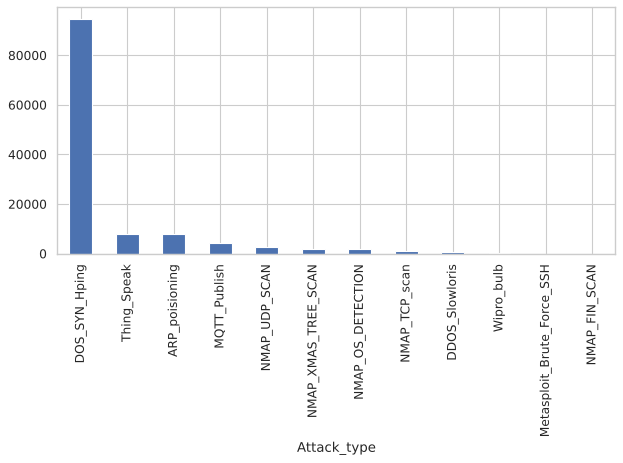

In [15]:
df["Attack_type"].value_counts().plot.bar(figsize=(9, 4))

### Using matplotlib

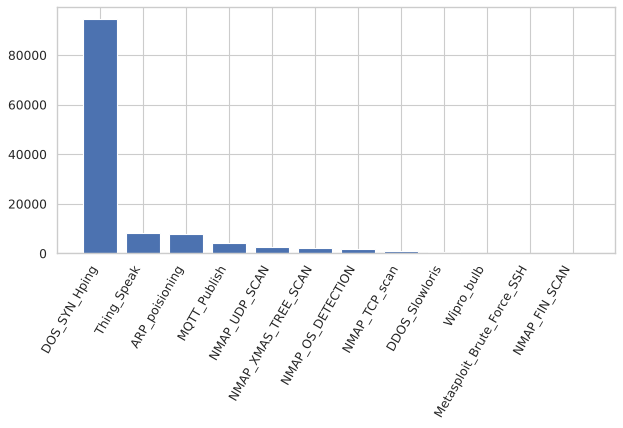

In [16]:
counts = df["Attack_type"].value_counts()
plt.figure(figsize=(9, 4))
plt.bar(counts.index, counts.values)
plt.xticks(rotation=60, ha="right")
plt.show()

### Using seaborn

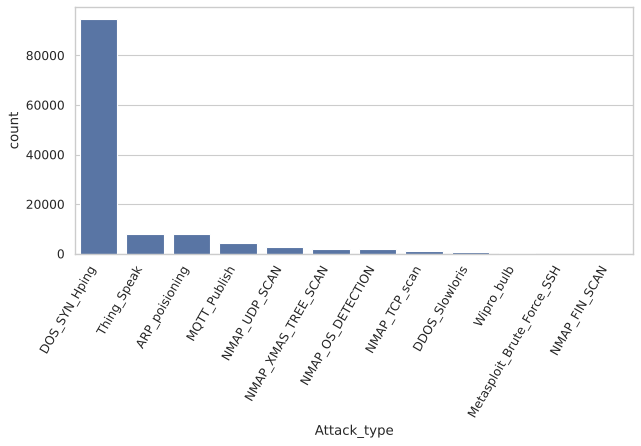

In [17]:
plt.figure(figsize=(9, 4))
sns.countplot(x="Attack_type", data=df, order=df["Attack_type"].value_counts().index)
plt.xticks(rotation=60, ha="right");

Số lượng chênh lệch rất lớn nên thử thêm **thang log** để thấy rõ các lớp hiếm:

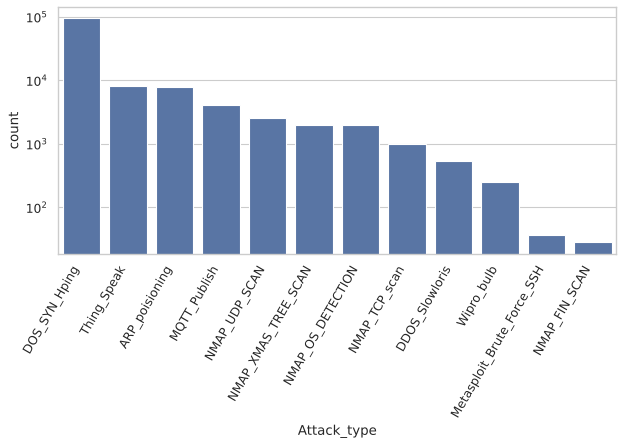

In [18]:
plt.figure(figsize=(9, 4))
ax = sns.countplot(x="Attack_type", data=df, order=df["Attack_type"].value_counts().index)
ax.set_yscale("log")
plt.xticks(rotation=60, ha="right");

### What we can conclude:

- Các lớp **rất mất cân bằng**: `DOS_SYN_Hping` chiếm khoảng **76.9%** (94.659 / 123.117 dòng).
- Nhiều lớp hiếm: `NMAP_FIN_SCAN` (28), `Metasploit_Brute_Force_SSH` (37), `Wipro_bulb` (253), `DDOS_Slowloris` (534).
- Chỉ số **accuracy sẽ gây hiểu lầm** (đoán toàn bộ là `DOS_SYN_Hping` đã đạt ~77%). Nên dùng precision/recall/F1 theo từng lớp, macro-F1, confusion matrix.
- Cần cân nhắc xử lý mất cân bằng (class weight, oversampling như SMOTE, undersampling) và chia dữ liệu theo **stratified**.
- Nhìn theo nhị phân thì tấn công chiếm khoảng 89.8%, bình thường khoảng 10.2%.

## **Categorical features: `proto` và `service`**

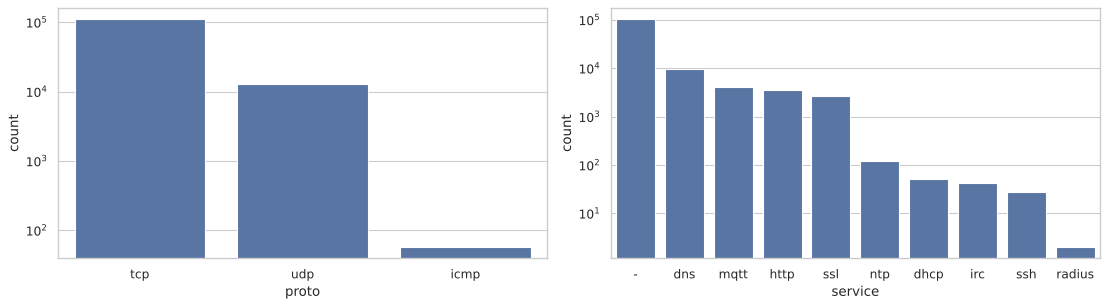

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(x="proto", data=df, ax=axes[0])
axes[0].set_yscale("log")
sns.countplot(x="service", data=df, order=df["service"].value_counts().index, ax=axes[1])
axes[1].set_yscale("log")
plt.tight_layout();

Giao thức `tcp` chiếm khoảng 89.7%, `udp` ~10.3%, `icmp` chỉ 57 dòng.
Cột `service` có tới ~83.5% giá trị là `-` (không xác định được dịch vụ).

## **Heatmap** (cho hai biến phân loại)

Tương tự phần Heatmap của Tutorial: xem mỗi loại `Attack_type` tập trung ở `proto` / `service` nào (tỉ lệ theo hàng).

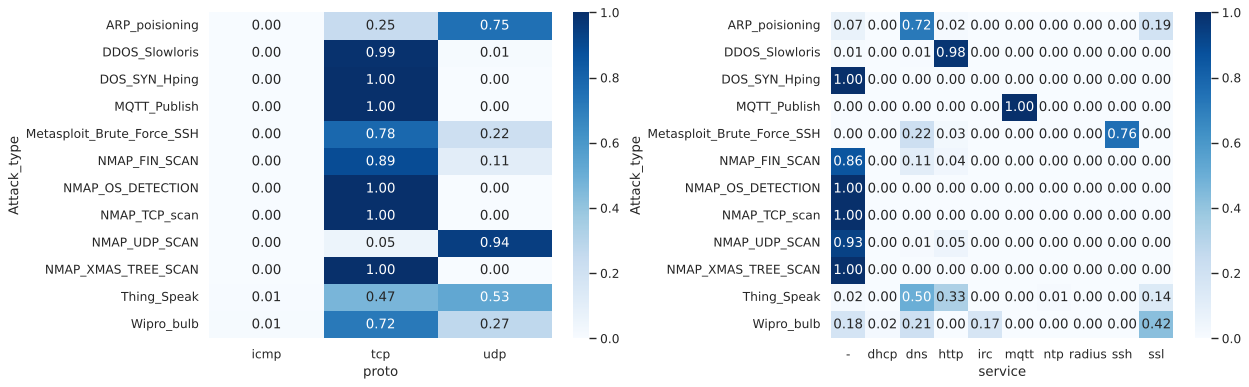

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(pd.crosstab(df["Attack_type"], df["proto"], normalize="index"),
            cmap="Blues", annot=True, fmt=".2f", ax=axes[0])
sns.heatmap(pd.crosstab(df["Attack_type"], df["service"], normalize="index"),
            cmap="Blues", annot=True, fmt=".2f", ax=axes[1])
plt.tight_layout();

### What we can conclude:

- `DOS_SYN_Hping`, `NMAP_OS_DETECTION`, `NMAP_TCP_scan`: **100% TCP** và service là `-` (flow SYN/probe không hoàn tất kết nối nên không nhận dạng được dịch vụ).
- `NMAP_UDP_SCAN` chủ yếu là **UDP** (~94%), `ARP_poisioning` chủ yếu UDP (~75%) với dịch vụ **DNS**.
- `MQTT_Publish` gần như toàn bộ có service `mqtt`; `DDOS_Slowloris` chủ yếu `http`; `Metasploit_Brute_Force_SSH` chủ yếu `ssh`.
- Nghĩa là `proto` và `service` là **đặc trưng phân biệt khá tốt** cho một số lớp, nhưng không đủ để tách các lớp khác (các kiểu Nmap đều mang service `-`).

## **Comparison graphs**

### Scatterplots

Vì dữ liệu lớn (123 nghìn dòng) và lệch mạnh nên ta **lấy mẫu 5.000 dòng** và dùng thang `symlog` (log nhưng vẫn vẽ được giá trị 0).

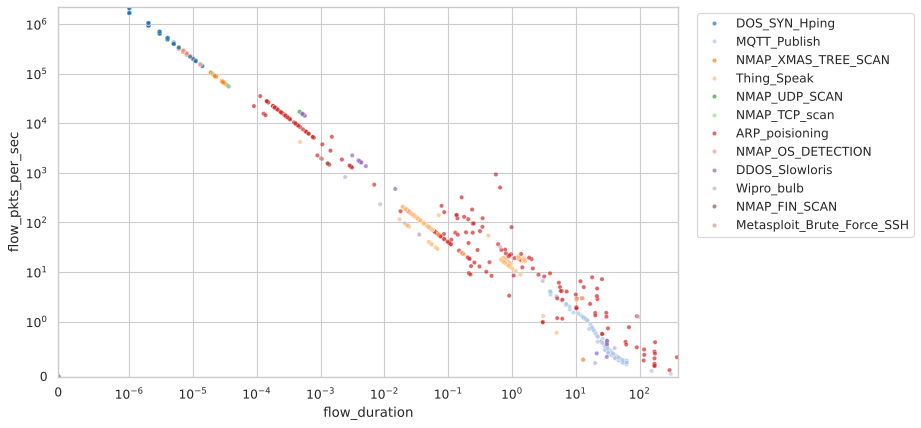

In [21]:
sample = df.sample(5000, random_state=42)

plt.figure(figsize=(10, 6))
ax = sns.scatterplot(x="flow_duration", y="flow_pkts_per_sec", hue="Attack_type",
                     palette="tab20", data=sample, s=15, alpha=0.7)
ax.set_xscale("symlog", linthresh=1e-6)
ax.set_yscale("symlog", linthresh=1)
ax.set_xlim(left=0); ax.set_ylim(bottom=0)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left");

### What we can conclude:

- Các điểm nằm gần một **đường thẳng trên thang log-log**: flow càng ngắn thì tốc độ gói càng cao. Đây là hệ quả tự nhiên vì đa số flow chỉ có vài gói, nên `flow_pkts_per_sec` xấp xỉ (số gói / thời gian).
- `DOS_SYN_Hping` nằm ở góc trên-trái (flow cỡ micro-giây, tốc độ gói rất cao), các kiểu Nmap nằm lân cận ở khoảng giữa-trái.
- `MQTT_Publish` (và `DDOS_Slowloris`) nằm ở góc dưới-phải: flow kéo dài hàng chục giây, tốc độ gói thấp.
- `Thing_Speak`, `ARP_poisioning`, `Wipro_bulb` nằm ở vùng giữa và **chồng lấn** nhau, nên cần thêm đặc trưng khác để phân biệt.
- Một số điểm có `flow_duration` = 0 và `flow_pkts_per_sec` = 0 (flow chỉ có 1 gói), nằm ở gốc tọa độ.

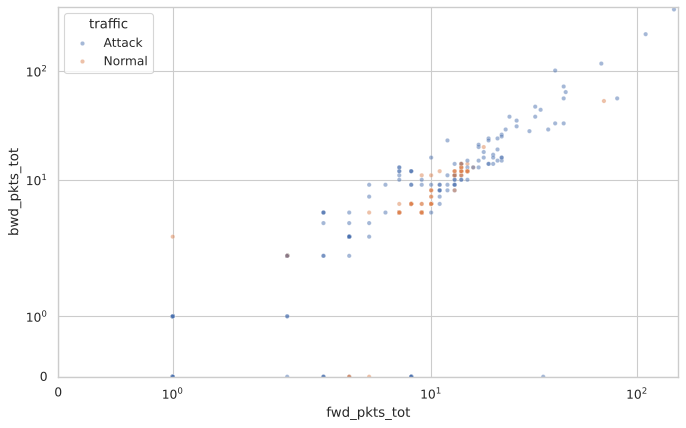

In [22]:
plt.figure(figsize=(10, 6))
ax = sns.scatterplot(x="fwd_pkts_tot", y="bwd_pkts_tot", hue="traffic", data=sample, s=15, alpha=0.5)
ax.set_xscale("symlog"); ax.set_yscale("symlog")
ax.set_xlim(left=0); ax.set_ylim(bottom=0);

Với góc nhìn nhị phân: flow tấn công và bình thường **chồng lấn nhiều** ở vùng ít gói. Số gói hai chiều của flow bình thường lớn hơn rõ rệt (trung vị khoảng 7 gói đi và 5 gói về), còn flow tấn công thường chỉ có 1 gói mỗi chiều (trung vị 1/1). Khoảng 13,5% flow tấn công không có gói phản hồi (`bwd_pkts_tot` = 0), so với khoảng 2,2% ở flow bình thường.

## **Correlogram**

Vẽ `pairplot` cho một nhóm nhỏ đặc trưng quan trọng (đã biến đổi `log1p` để dễ nhìn, lấy mẫu 3.000 dòng).

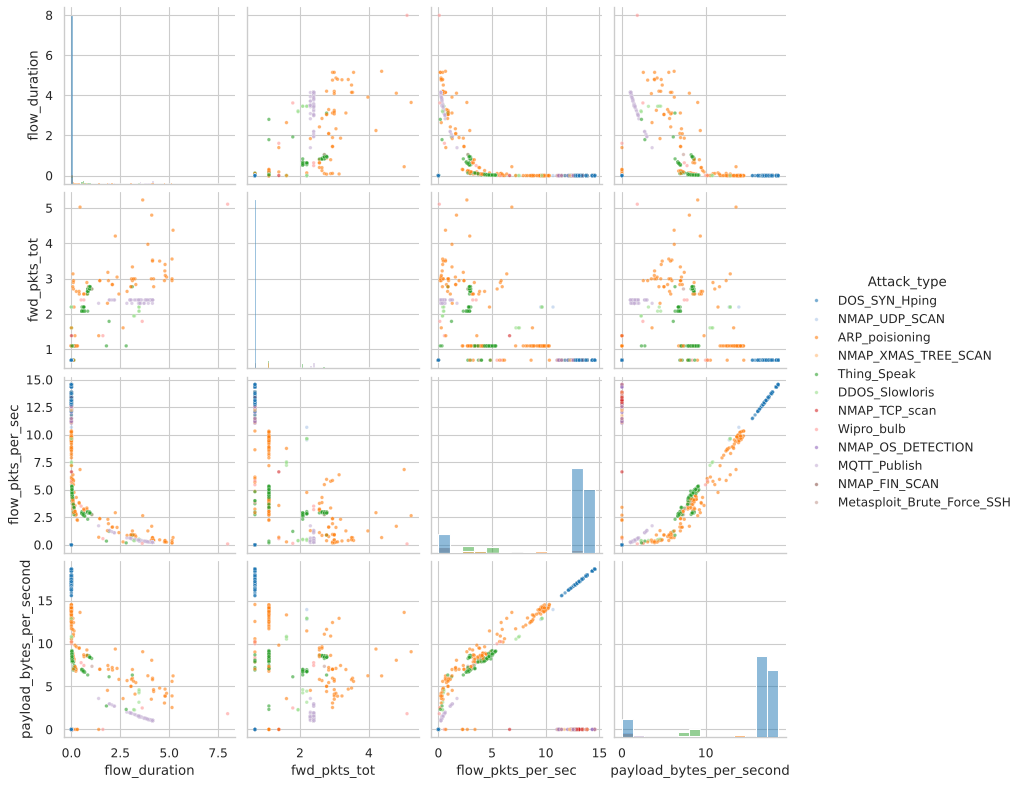

In [23]:
feats = ["flow_duration", "fwd_pkts_tot", "flow_pkts_per_sec", "payload_bytes_per_second"]
small = np.log1p(df[feats].sample(3000, random_state=0))
small["Attack_type"] = df.loc[small.index, "Attack_type"]
sns.pairplot(small, hue="Attack_type", palette="tab20", diag_kind="hist", plot_kws={"s": 10, "alpha": 0.6});

### What we can conclude:

- Các điểm dữ liệu nằm dọc theo **các đường cong liên tục** chứ không tách thành cụm rời nhau: `flow_pkts_per_sec` và `payload_bytes_per_second` tương quan thuận rất mạnh, còn `flow_duration` tương quan nghịch với tốc độ gói.
- `DOS_SYN_Hping` chiếm gần hết biểu đồ phân phối (đường chéo) và nằm ở đầu trên của tốc độ gói; do lớp này quá lớn nên các lớp nhỏ bị che khuất, đây là một lý do nữa cần xem từng lớp riêng.
- Các kiểu Nmap không có payload nên nằm ở hàng `payload_bytes_per_second` = 0, chỉ có thể phân biệt với nhau nhờ các đặc trưng khác (thời gian, tốc độ gói, cờ TCP).
- `MQTT_Publish` tạo một đường riêng ở vùng flow dài, tốc độ gói thấp; các lớp còn lại chồng lấn ở vùng giữa.

## **Heatmap** (tương quan giữa các đặc trưng số)

Ma trận đầy đủ 82 x 82 (ẩn nửa trên, không hiển thị số):

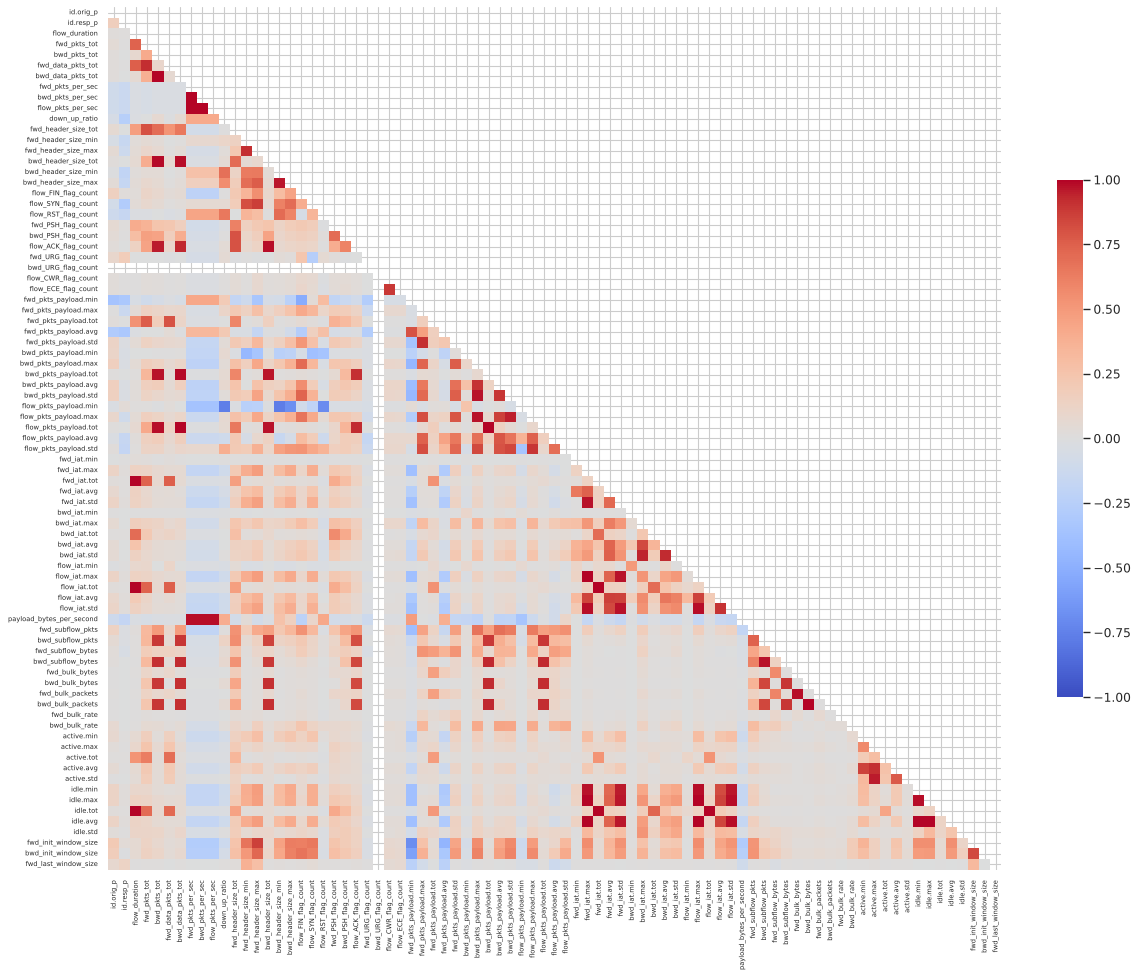

In [24]:
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(18, 14))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            xticklabels=True, yticklabels=True, cbar_kws={"shrink": 0.6})
plt.xticks(fontsize=6); plt.yticks(fontsize=6);

Và heatmap có chú thích số cho nhóm đặc trưng chọn lọc:

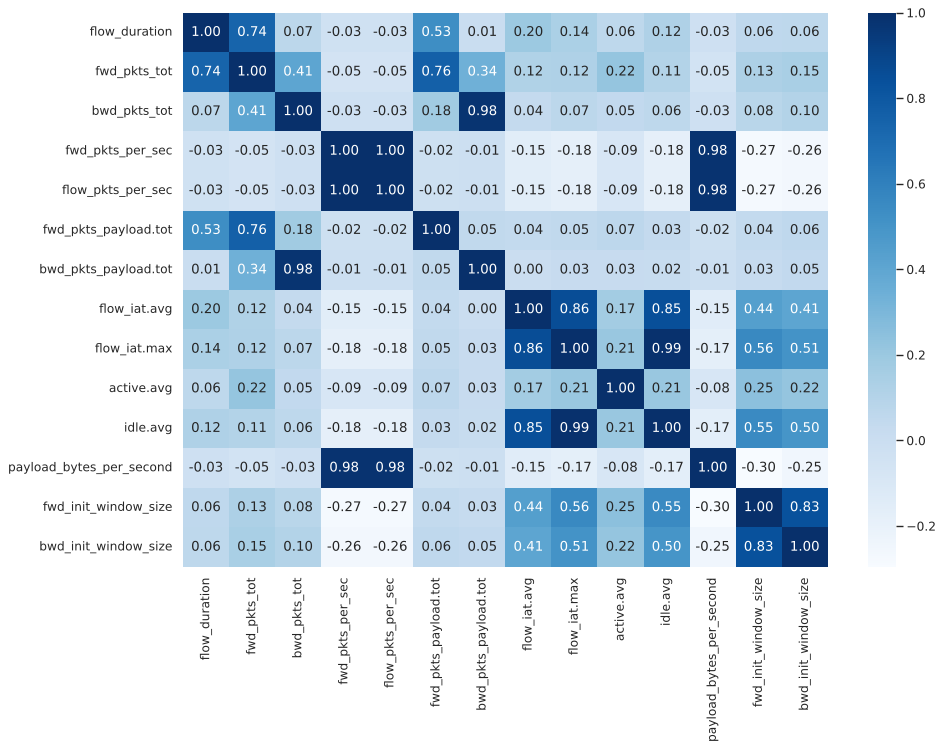

In [25]:
sel = ["flow_duration", "fwd_pkts_tot", "bwd_pkts_tot", "fwd_pkts_per_sec", "flow_pkts_per_sec",
       "fwd_pkts_payload.tot", "bwd_pkts_payload.tot", "flow_iat.avg", "flow_iat.max",
       "active.avg", "idle.avg", "payload_bytes_per_second", "fwd_init_window_size", "bwd_init_window_size"]
fig = plt.figure(figsize=(13, 9))
sns.heatmap(df[sel].corr(), cmap="Blues", annot=True, fmt=".2f");

### What we can conclude:

- Các hàng/cột **trắng** trên heatmap là cột hằng số `bwd_URG_flag_count` (không có phương sai nên không tính được tương quan).
- Xuất hiện **các khối tương quan mạnh** (các đặc trưng về thời gian IAT/active/idle; các đặc trưng về số gói và kích thước).
- Có 52 cặp |corr| > 0.95, gồm các cặp gần như trùng nhau: `flow_duration` & `flow_iat.tot`, `fwd/bwd/flow_pkts_per_sec`.
- Hệ quả: dữ liệu **đa cộng tuyến cao**. Trước khi mô hình hóa nên **loại bớt đặc trưng dư thừa** (feature selection), loại cột hằng số `bwd_URG_flag_count`, hoặc dùng PCA/mô hình dạng cây (ít nhạy với đa cộng tuyến).

## **Histograms and distributions**

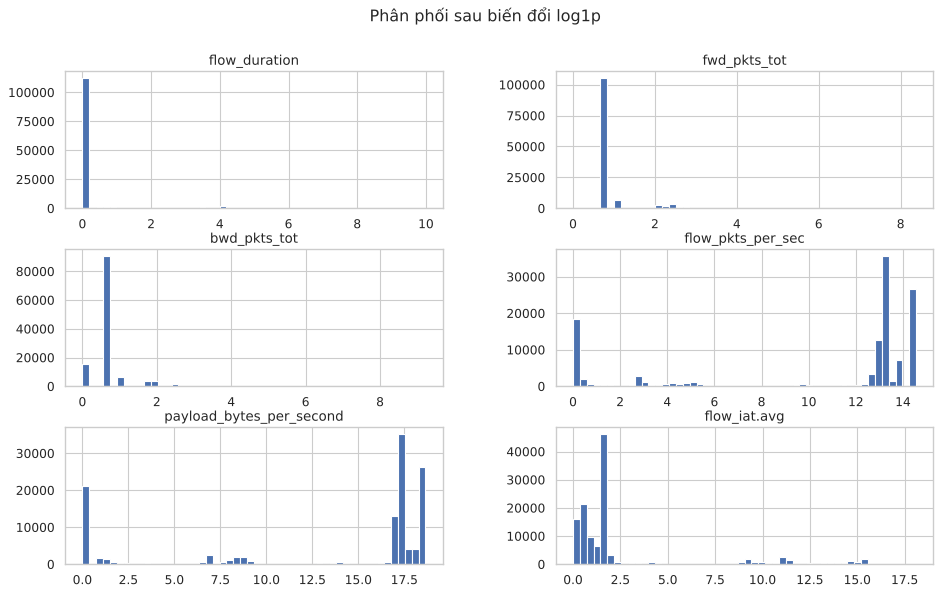

In [26]:
cols = ["flow_duration", "fwd_pkts_tot", "bwd_pkts_tot", "flow_pkts_per_sec",
        "payload_bytes_per_second", "flow_iat.avg"]
np.log1p(df[cols]).hist(bins=50, figsize=(14, 8))
plt.suptitle("Phân phối sau biến đổi log1p");

Phân phối gốc lệch phải rất mạnh (độ lệch - skewness của nhiều cột lên tới hàng trăm), nên ở đây vẽ sau khi biến đổi `log1p`. 
Ngay cả sau biến đổi, nhiều đặc trưng vẫn **đa đỉnh** (multimodal), phản ánh việc dữ liệu gộp nhiều kiểu hành vi khác nhau (tấn công vs bình thường).

## **Boxplots and violins**

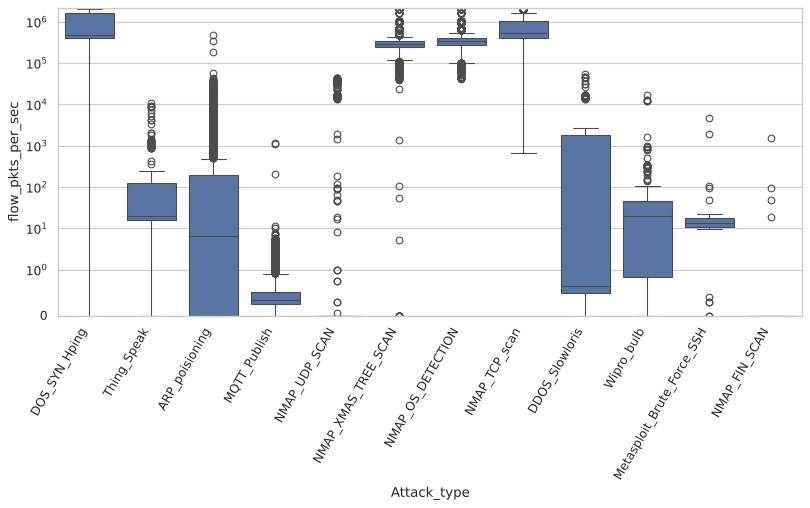

In [27]:
plt.figure(figsize=(12, 5))
ax = sns.boxplot(x="Attack_type", y="flow_pkts_per_sec", data=df,
                 order=df["Attack_type"].value_counts().index)
ax.set_yscale("symlog", linthresh=1)
ax.set_ylim(bottom=0)
plt.xticks(rotation=60, ha="right");

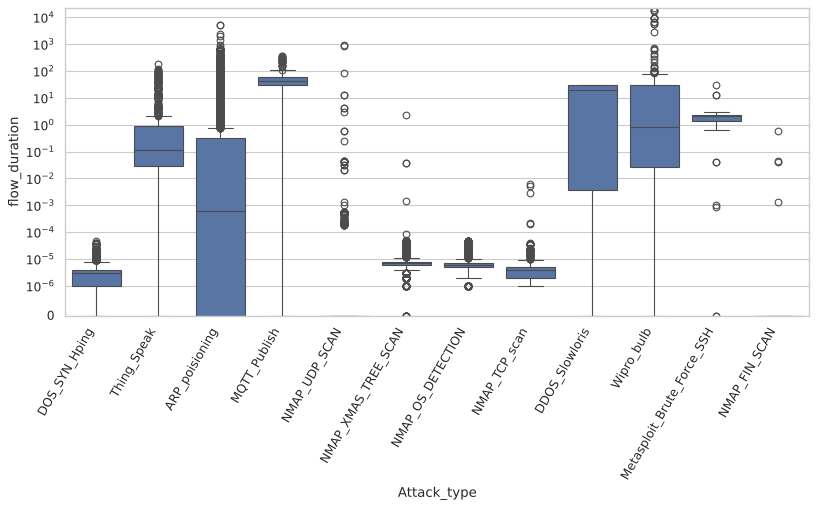

In [28]:
plt.figure(figsize=(12, 5))
ax = sns.boxplot(x="Attack_type", y="flow_duration", data=df,
                 order=df["Attack_type"].value_counts().index)
ax.set_yscale("symlog", linthresh=1e-6)
ax.set_ylim(bottom=0)
plt.xticks(rotation=60, ha="right");

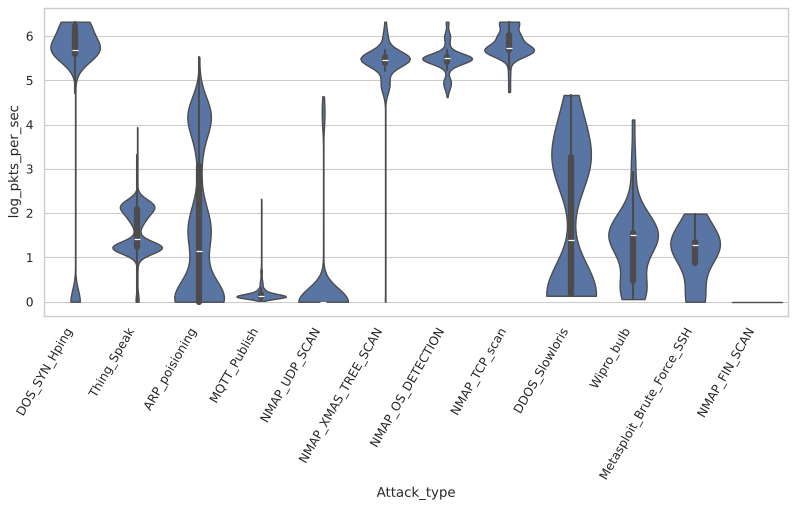

In [29]:
plot_df = df.sample(20000, random_state=1).copy()
plot_df["log_pkts_per_sec"] = np.log10(1 + plot_df["flow_pkts_per_sec"])
plt.figure(figsize=(12, 5))
sns.violinplot(x="Attack_type", y="log_pkts_per_sec", data=plot_df,
               order=df["Attack_type"].value_counts().index, cut=0, density_norm="width")
plt.xticks(rotation=60, ha="right");

### What we can conclude:

- `DOS_SYN_Hping` và các kiểu Nmap có tốc độ gói **cực cao** (hàng trăm nghìn gói/giây) với thời gian flow tính bằng micro-giây.
- `MQTT_Publish` có flow **dài (trung vị khoảng 44 giây)** và tốc độ gói rất thấp (trung vị 0,35 gói/giây). `DDOS_Slowloris` cũng có flow dài (trung vị khoảng 20 giây) nhưng độ phân tán lớn: trung vị chỉ 0,65 gói/giây trong khi phân vị trên lên tới hàng nghìn.
- `NMAP_UDP_SCAN` và `NMAP_FIN_SCAN` có trung vị `flow_duration` và `flow_pkts_per_sec` bằng 0 (flow chỉ có 1 gói).
- Có **rất nhiều outlier** ở hầu hết các lớp. Trong bài toán phát hiện tấn công, các outlier này thường chính là thông tin quan trọng, nên cần cẩn thận khi loại bỏ.

# **Tóm tắt các phát hiện chính của EDA**

| Vấn đề | Phát hiện | Gợi ý xử lý |
|---|---|---|
| Kích thước | 123.117 dòng x 84 cột, không có missing | Không cần impute |
| Trùng lặp | 5.195 dòng (4,2%), chủ yếu `DOS_SYN_Hping` | Cân nhắc giữ nguyên hoặc loại tùy mục tiêu |
| Mất cân bằng lớp | `DOS_SYN_Hping` ~76,9%; có lớp chỉ 28-37 mẫu | Stratified split, class weight/SMOTE, dùng macro-F1 |
| Phân phối | Lệch phải cực mạnh, đa đỉnh | Biến đổi log, scaling |
| Đa cộng tuyến | 52 cặp \|corr\| > 0.95; 1 cột hằng số | Loại cột dư, PCA hoặc mô hình cây |
| Biến phân loại | `proto`, `service` phân biệt tốt một số lớp | One-hot / target encoding |
| Khả năng phân tách | Flood/quét tách rõ khỏi bình thường; một số lớp chồng lấn (`Thing_Speak`, `Wipro_bulb`, `ARP_poisioning`) | Kỳ vọng nhầm lẫn chủ yếu giữa các lớp này |